# Red neuronal de clasificación: ambiente tectónico de rocas volcánicas

**Unidad 4 · Machine Learning** · Geoquímica de rocas con datos de EarthChem PetDB · Estadística y Probabilidades,
FIGEMPA – UCE. Proyecto estrictamente académico.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crisrumiguano-art/geoquimica-earthchem-ml/blob/main/notebooks/02_clasificacion_ambiente.ipynb)

Reconocer el **ambiente tectónico** (dorsal, intraplaca o margen convergente) de una roca volcánica con sus 8 óxidos mayores.

**Cómo usarlo:** en Colab, *Entorno de ejecución → Ejecutar todas*. Tarda unos minutos.

## 0. Clasificación con una red neuronal

En la clasificación la salida no es un número sino una **categoría**. La última capa tiene una neurona por clase y la
función **softmax** convierte sus salidas en probabilidades que suman 1; la red elige la más probable. Es la extensión de
la regresión logística (una neurona con activación sigmoide) a varias clases.

**Problema:** los geólogos usan diagramas de discriminación para saber en qué ambiente tectónico se formó una roca
volcánica antigua cuyo contexto se perdió. ¿Puede una red reconocer el ambiente (**dorsal**, **intraplaca** o **margen
convergente**) solo con los óxidos mayores?

## 1. Librerías y carga de datos

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(2026)        # semilla: los resultados se pueden repetir

# Base de datos: si se corre en el repositorio usa la copia local; en Colab la descarga de GitHub (26 MB)
local = "../data/earthchem_limpio.csv.gz"
url = "https://github.com/crisrumiguano-art/geoquimica-earthchem-ml/raw/main/data/earthchem_limpio.csv.gz"
base = pd.read_csv(local if os.path.exists(local) else url, low_memory=False)
print(base.shape)

# Las figuras se guardan para la web solo cuando se corre dentro del repositorio
WEB = "../docs/img/ml" if os.path.isdir("../docs") else None
if WEB:
    os.makedirs(WEB, exist_ok=True)
def guardar(nombre):
    if WEB:
        plt.savefig(f"{WEB}/{nombre}.png", dpi=130, bbox_inches="tight")

(159760, 75)


## 2. Preprocesamiento

- Rocas **volcánicas** con los 8 óxidos mayores completos; sin la clase «mixto» (ambiente ambiguo).
- **Codificación**: cada clase se convierte en un número (0, 1, 2).
- **Balance de clases**: las tres clases no tienen el mismo tamaño; se da más peso a las menos frecuentes para que la red
  no aprenda solo la mayoritaria.
- División 70 / 15 / 15 estratificada (cada parte con las mismas proporciones de clase) y normalización.

In [2]:
ENTRADAS = ["SiO2 (wt%)", "Al2O3 (wt%)", "MgO (wt%)", "CaO (wt%)", "Na2O (wt%)", "K2O (wt%)", "P2O5 (wt%)", "MnO (wt%)"]
volcanicas = base["Sample Type"].astype(str).str.startswith("igneous:volcanic")
datos = base.loc[volcanicas, ENTRADAS + ["Tectonic Group"]].dropna()
datos = datos[datos["Tectonic Group"] != "mixto"]
CLASES = sorted(datos["Tectonic Group"].unique())
y = datos["Tectonic Group"].map({c: i for i, c in enumerate(CLASES)}).values
X = datos[ENTRADAS].values
print(datos["Tectonic Group"].value_counts())

X_ent, X_resto, y_ent, y_resto = train_test_split(X, y, test_size=0.30, random_state=2026, stratify=y)
X_val, X_prueba, y_val, y_prueba = train_test_split(X_resto, y_resto, test_size=0.50, random_state=2026, stratify=y_resto)
escala = StandardScaler().fit(X_ent)
X_ent, X_val, X_prueba = escala.transform(X_ent), escala.transform(X_val), escala.transform(X_prueba)
pesos = {i: len(y_ent) / (len(CLASES) * np.sum(y_ent == i)) for i in range(len(CLASES))}   # balance de clases
print("pesos por clase:", {CLASES[i]: round(w, 2) for i, w in pesos.items()})

Tectonic Group
intraplaca y rift            12556
dorsal y corteza oceanica     9684
margen convergente            9363
Name: count, dtype: int64
pesos por clase: {'dorsal y corteza oceanica': np.float64(1.09), 'intraplaca y rift': np.float64(0.84), 'margen convergente': np.float64(1.13)}


## 3. Arquitectura de la red

Tres capas ocultas (128, 64 y 32 neuronas, ReLU) con *dropout* y una salida softmax de 3 neuronas. Antes de fijarla se
probaron otras con Optuna; esta es la mejor de las probadas, con un buen equilibrio entre exactitud y tiempo.

In [3]:
%pip install -q optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def crear_red(neuronas, tasa, abandono):
    red = keras.Sequential([layers.Input(shape=(X_ent.shape[1],)),
                            layers.Dense(neuronas, activation="relu"), layers.Dropout(abandono),
                            layers.Dense(neuronas // 2, activation="relu"), layers.Dropout(abandono),
                            layers.Dense(neuronas // 4, activation="relu"),
                            layers.Dense(len(CLASES), activation="softmax")])
    red.compile(optimizer=keras.optimizers.Adam(tasa), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return red

def objetivo(prueba):
    red = crear_red(prueba.suggest_categorical("neuronas", [64, 128, 256]),
                    prueba.suggest_float("tasa_aprendizaje", 1e-4, 1e-2, log=True),
                    prueba.suggest_float("abandono", 0.0, 0.3))
    h = red.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=30, batch_size=256, verbose=0, class_weight=pesos,
                callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return max(h.history["val_accuracy"])

estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=2026))
estudio.optimize(objetivo, n_trials=15)
p = estudio.best_params
print("mejores hiperparámetros:", p, " exactitud de validación:", round(estudio.best_value, 3))
red = crear_red(p["neuronas"], p["tasa_aprendizaje"], p["abandono"])
red.summary()


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\dalem\venv-geoml\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


mejores hiperparámetros: {'neuronas': 256, 'tasa_aprendizaje': 0.0019310516922620845, 'abandono': 0.07078008023187397}  exactitud de validación: 0.863


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_60 (Dense)                │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,651 (170.51 KB)

 Trainable params: 43,651 (170.51 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento

épocas entrenadas: 57


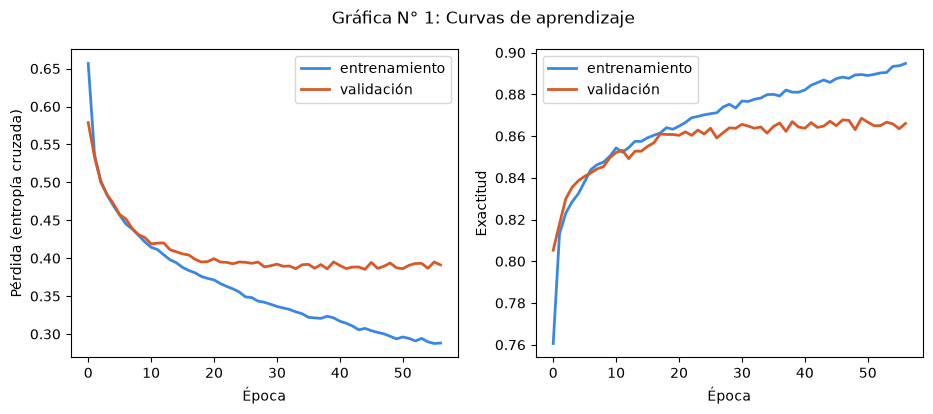

In [4]:
historia = red.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=150, batch_size=256, verbose=0,
                   class_weight=pesos, callbacks=[keras.callbacks.EarlyStopping(patience=12, restore_best_weights=True)])
print("épocas entrenadas:", len(historia.history["loss"]))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(historia.history["loss"], color="#3987e5", lw=2, label="entrenamiento")
ejes[0].plot(historia.history["val_loss"], color="#d95926", lw=2, label="validación")
ejes[0].set_xlabel("Época"); ejes[0].set_ylabel("Pérdida (entropía cruzada)"); ejes[0].legend()
ejes[1].plot(historia.history["accuracy"], color="#3987e5", lw=2, label="entrenamiento")
ejes[1].plot(historia.history["val_accuracy"], color="#d95926", lw=2, label="validación")
ejes[1].set_xlabel("Época"); ejes[1].set_ylabel("Exactitud"); ejes[1].legend()
fig.suptitle("Gráfica N° 1: Curvas de aprendizaje")
guardar("clas_curvas"); plt.show()

## 5. Evaluación con los datos de prueba

Exactitud = 0.867   Kappa de Cohen = 0.799

                           precision    recall  f1-score   support

dorsal y corteza oceanica      0.818     0.878     0.847      1453
        intraplaca y rift      0.911     0.857     0.883      1884
       margen convergente      0.865     0.868     0.866      1404

                 accuracy                          0.867      4741
                macro avg      0.865     0.868     0.866      4741
             weighted avg      0.869     0.867     0.867      4741



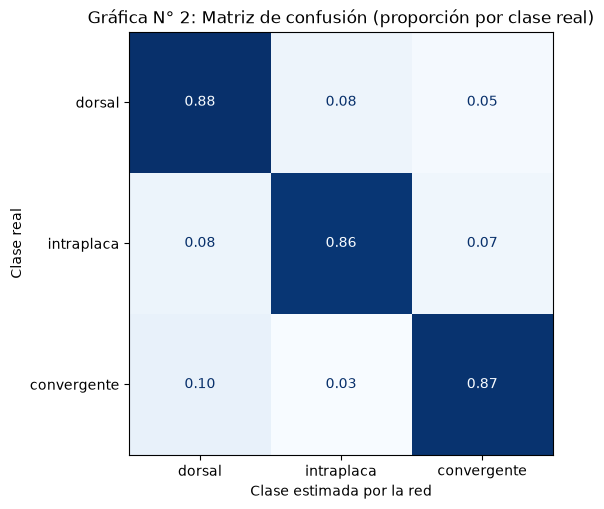

In [5]:
from sklearn.metrics import accuracy_score, cohen_kappa_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
pred = red.predict(X_prueba, verbose=0).argmax(axis=1)
exactitud = accuracy_score(y_prueba, pred)
kappa = cohen_kappa_score(y_prueba, pred)          # acuerdo descontando el azar: > 0,6 es bueno, > 0,8 muy bueno
print(f"Exactitud = {exactitud:.3f}   Kappa de Cohen = {kappa:.3f}\n")
print(classification_report(y_prueba, pred, target_names=CLASES, digits=3))
fig, eje = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_prueba, pred, normalize="true"), display_labels=["dorsal", "intraplaca", "convergente"]).plot(
    ax=eje, cmap="Blues", values_format=".2f", colorbar=False)
eje.set_title("Gráfica N° 2: Matriz de confusión (proporción por clase real)")
eje.set_xlabel("Clase estimada por la red"); eje.set_ylabel("Clase real")
guardar("clas_confusion"); plt.show()

**Cómo leer la matriz:** cada fila es la clase real y suma 1; la diagonal es la proporción bien clasificada. Lo que
queda fuera de la diagonal muestra qué ambientes se confunden entre sí.

## 6. Comparación con la regresión logística

La regresión logística multiclase (de la plantilla del curso) es una red sin capas ocultas: una sola capa de neuronas con
softmax. Se compara con los mismos datos de prueba.

             modelo  exactitud  kappa
Regresión logística      0.744  0.617
       Red neuronal      0.867  0.799


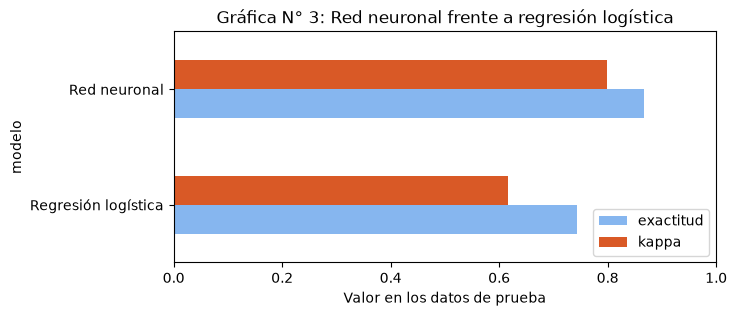

In [6]:
from sklearn.linear_model import LogisticRegression
logistica = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_ent, y_ent)
p_log = logistica.predict(X_prueba)
comparacion = pd.DataFrame({"modelo": ["Regresión logística", "Red neuronal"],
                            "exactitud": [accuracy_score(y_prueba, p_log), exactitud],
                            "kappa": [cohen_kappa_score(y_prueba, p_log), kappa]})
print(comparacion.round(3).to_string(index=False))
comparacion.set_index("modelo").plot.barh(figsize=(7, 3), color=["#86b6ef", "#d95926"], xlim=(0, 1))
plt.title("Gráfica N° 3: Red neuronal frente a regresión logística"); plt.xlabel("Valor en los datos de prueba")
guardar("clas_comparacion"); plt.show()

## 7. Predicción interactiva

In [7]:
import ipywidgets as widgets
from IPython.display import display
valores = [50.0, 15.0, 8.0, 11.0, 2.5, 0.3, 0.2, 0.17]
casillas = [widgets.FloatText(value=v, description=n.split(" ")[0], layout=widgets.Layout(width="200px"))
            for n, v in zip(ENTRADAS, valores)]
boton = widgets.Button(description="Clasificar", button_style="warning")
salida = widgets.Output()
def clasificar(_):
    with salida:
        salida.clear_output()
        prob = red.predict(escala.transform([[c.value for c in casillas]]), verbose=0)[0]
        for c, pr in sorted(zip(CLASES, prob), key=lambda t: -t[1]):
            print(f"{c:28s} {pr * 100:5.1f} %")
boton.on_click(clasificar)
display(widgets.VBox(casillas + [boton, salida]))
clasificar(None)

In [8]:
# Ejemplos sin widgets: un basalto de dorsal, un basalto de isla oceánica y una andesita de arco
ejemplos = pd.DataFrame([[50.0, 15.0, 8.0, 11.0, 2.5, 0.15, 0.12, 0.17],
                         [47.0, 13.5, 8.5, 10.5, 2.8, 1.1, 0.5, 0.18],
                         [59.0, 17.0, 3.0, 6.5, 3.5, 1.5, 0.2, 0.12]], columns=ENTRADAS,
                        index=["basalto de dorsal (MORB)", "basalto de isla oceánica", "andesita de arco"])
prob = red.predict(escala.transform(ejemplos[ENTRADAS].values), verbose=0)
for nombre, pr in zip(ejemplos.index, prob):
    print(f"{nombre:28s} -> {CLASES[pr.argmax()]} ({pr.max() * 100:.0f} %)")
if WEB:
    reporte = classification_report(y_prueba, pred, target_names=CLASES, output_dict=True)
    json.dump({"clasificacion": {"n": int(len(datos)), "exactitud": round(float(exactitud), 3), "kappa": round(float(kappa), 3),
                                 "hiperparametros": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in p.items()},
                                 "por_clase": {c: round(reporte[c]["f1-score"], 3) for c in CLASES},
                                 "comparacion": comparacion.round(3).to_dict("records"),
                                 "ejemplos": {n: CLASES[pr.argmax()] for n, pr in zip(ejemplos.index, prob)}}},
              open("../docs/data/ml_clasificacion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

basalto de dorsal (MORB)     -> dorsal y corteza oceanica (99 %)
basalto de isla oceánica     -> intraplaca y rift (85 %)
andesita de arco             -> margen convergente (99 %)


## 8. Conclusión

Con solo los ocho óxidos mayores, la red reconoce el ambiente tectónico de una roca volcánica en más de 8 de cada 10
casos que nunca vio, con un kappa cercano a 0,8 (acuerdo muy bueno), muy por encima de la regresión logística. Los tres
ambientes se reconocen parecido (86–88 % de aciertos por clase); la confusión más frecuente es tomar un margen
convergente por dorsal, porque los dos tienen basaltos pobres en potasio. En las curvas de aprendizaje, la pérdida de
validación deja de bajar hacia la época 20 mientras la de entrenamiento sigue bajando: es el comienzo del sobreajuste, y
la parada temprana se queda con los pesos de la mejor época. Límite: la base tiene más rocas oceánicas que
continentales, así que la red refleja ese sesgo.